# Сегментация клиентов торгового центра

Сравнение KMeans, агломеративной кластеризации и KMeans после PCA на данных о возрасте, годовом доходе и индексе расходов покупателей. Цель — выделить группы клиентов и сформулировать проверяемые гипотезы для персональных предложений.

В исходном наборе 205 строк. После проверки качества и удаления пяти строк с пропусками в анализе остаются 200 клиентов. Итоговая модель — KMeans на трёх стандартизированных признаках: шесть кластеров, коэффициент силуэта 0,428. PCA до двух компонент не улучшил этот показатель.

Для запуска установите зависимости из `requirements.txt`, поместите исходный `customers.csv` в папку `data` и выполняйте ячейки по порядку из папки проекта. Ноутбук содержит сохранённые результаты. Проект основан на учебном наборе: исходное происхождение и лицензия этой версии CSV не подтверждены; бизнес-эффект предложений не измерялся.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from IPython.display import display


pd.set_option("display.max_columns", 500)
pd.set_option("display.max_colwidth", 10000)
features = ["age", "annual_income", "spending_score"]


## 1. Качество данных

Проверим структуру, пропуски, полные дубликаты и потенциальные выбросы по правилу 1,5 × IQR. Индекс расходов должен находиться в диапазоне 1–100. Ошибочное значение заменим на пропуск, строки с пропусками удалим. Правдоподобные крайние значения дохода сохраним.

In [2]:
from pathlib import Path

PATH = Path("data/customers.csv")
if not PATH.is_file():
    raise FileNotFoundError(
        "Поместите исходный customers.csv в папку data; подробности — в data/README.md."
    )
df_imported = pd.read_csv(PATH)
print(f"Данные загружены: {df_imported.shape[0]} строк, {df_imported.shape[1]} столбцов")


Данные загружены: 205 строк, 5 столбцов


In [3]:
df = df_imported.copy()

In [4]:
df.head()

,customer_id,gender,age,annual_income,spending_score
0,1,Male,19.0,15.0,39.0
1,2,Male,21.0,15.0,81.0
2,3,Female,20.0,16.0,6.0
3,4,Female,23.0,16.0,77.0
4,5,Female,31.0,17.0,40.0


In [5]:
df.notna().sum()

customer_id       205
gender            205
age               203
annual_income     203
spending_score    204
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.describe()

,customer_id,age,annual_income,spending_score
count,205.000000,203.000000,203.000000,204.000000
mean,103.000000,38.921182,60.413793,50.490196
std,59.322565,14.232987,26.914905,26.210871
min,1.000000,18.000000,9.000000,1.000000
25%,52.000000,28.500000,40.000000,34.750000
50%,103.000000,36.000000,61.000000,50.000000
75%,154.000000,49.000000,78.000000,73.000000
max,205.000000,80.000000,137.000000,120.000000


In [8]:
df[df["spending_score"] > 100]

,customer_id,gender,age,annual_income,spending_score
203,204,Male,NaN,16.0,120.0


In [9]:
df.loc[df["spending_score"] > 100, 'spending_score'] = np.nan
df[df.isna().any(axis=1)]

,customer_id,gender,age,annual_income,spending_score
200,201,Female,21.0,NaN,40.0
201,202,Female,30.0,127.0,NaN
202,203,Male,80.0,NaN,20.0
203,204,Male,NaN,16.0,NaN
204,205,Female,NaN,9.0,80.0


In [10]:
outlier_mask = pd.Series(False, index=df.index)

for col in features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    col_outliers = (df[col] < lower) | (df[col] > upper)
    outlier_mask |= col_outliers

    print(f"{col}: границы [{lower:.2f}, {upper:.2f}], выбросов: {col_outliers.sum()}")

outliers = df.loc[outlier_mask]
outliers

age: границы [-2.25, 79.75], выбросов: 1
annual_income: границы [-17.00, 135.00], выбросов: 2
spending_score: границы [-23.25, 130.75], выбросов: 0


,customer_id,gender,age,annual_income,spending_score
198,199,Male,32.0,137.0,18.0
199,200,Male,30.0,137.0,83.0
202,203,Male,80.0,NaN,20.0


In [11]:
# Сохраняем исходный df_imported; удаляем строки с пропусками из рабочей копии.
rows_before = len(df)
missing_before = df.isna().sum()
df = df.dropna().copy()

print("Пропуски до удаления строк:")
display(missing_before)
print(f"Удалено строк с пропусками: {rows_before - len(df)}")
print(f"Осталось клиентов: {len(df)}")
print("Пропусков после очистки:", df.isna().sum().sum())
assert not df.isna().any().any()


Пропуски до удаления строк:


customer_id       0
gender            0
age               2
annual_income     2
spending_score    2
dtype: int64

Удалено строк с пропусками: 5
Осталось клиентов: 200
Пропусков после очистки: 0


**Вывод:** Исходный датасет содержит 205 клиентов и 5 признаков; полных дубликатов нет. Значение `spending_score = 120` выходит за допустимый диапазон 1–100 и заменено на `NaN`. После замены в пяти строках было шесть пропусков: по два в возрасте, доходе и индексе расходов. Эти пять строк удалены; для дальнейшего анализа осталось 200 клиентов без пропусков. Заполнение значений не применялось, исходный `df_imported` сохранён.

По правилу IQR до очистки выделялись возраст 80 лет и два значения дохода 137 тыс. долларов. Строка с возрастом 80 лет удалена из-за пропущенного дохода. Два значения дохода 137 тыс. долларов превышают верхнюю границу по правилу IQR. Они рассмотрены как потенциальные выбросы, но сохранены: значения правдоподобны и могут характеризовать отдельный сегмент покупателей. Подтверждённых ошибок в этих строках не обнаружено.

## 2. Распределения и попарные связи

Построим гистограммы и диаграммы рассеяния для возраста, дохода и индекса расходов. Оценим, какие сочетания признаков позволяют визуально различать группы клиентов.

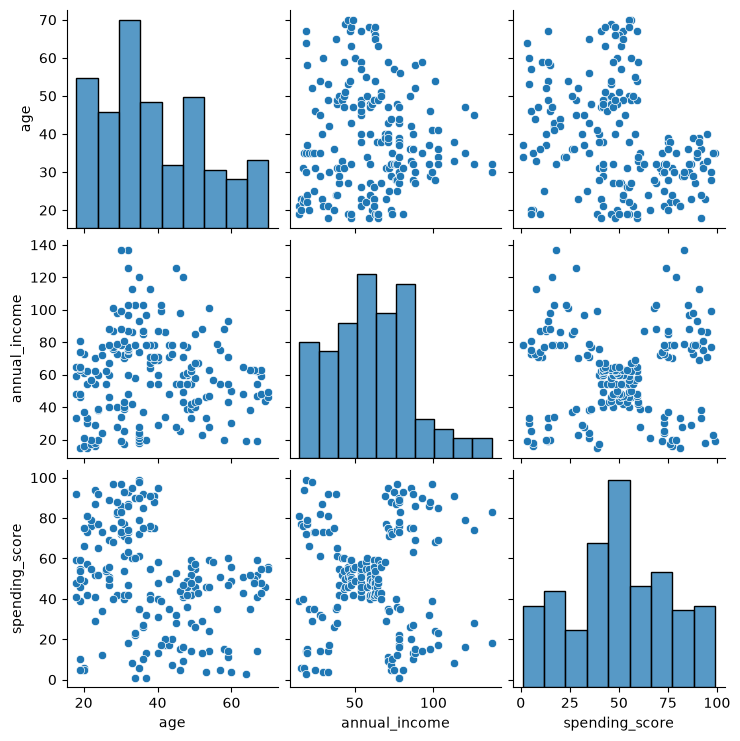

In [12]:
sns.pairplot(
    df[features],
    diag_kind="hist"
)
plt.show()

**Вывод:** Самые заметные группы видны на диаграмме дохода и индекса расходов: прослеживаются около пяти скоплений с разными сочетаниями этих признаков. Высокий доход не всегда сопровождается высоким индексом расходов. Возраст может уточнить разделение: наиболее высокие значения индекса расходов чаще встречаются у молодых клиентов. Для кластеризации выбраны все три числовых признака. Графики построены по 200 клиентам после удаления строк с пропусками; пять групп — предварительная визуальная оценка.

## 3. Структура данных в трёх измерениях

Интерактивный график показывает клиентов в исходных единицах измерения. Рассмотрим форму скоплений и промежутки между ними, чтобы выбрать методы для сравнения.

In [13]:
fig = px.scatter_3d(
    df,
    x="age",
    y="annual_income",
    z="spending_score",
    hover_name="customer_id",
    labels={
        "age": "Возраст",
        "annual_income": "Годовой доход, тыс. $",
        "spending_score": "Индекс расходов"
    },
    title="Клиенты в пространстве трёх признаков",
    opacity=0.7,
    height=650
)

fig.update_traces(marker=dict(size=4))
# Нативный вывод Plotly для VS Code/Jupyter и HTML с встроенной библиотекой для Colab.
try:
    import google.colab
except ImportError:
    fig.show(renderer="plotly_mimetype")
else:
    from IPython.display import HTML
    display(HTML(fig.to_html(full_html=False, include_plotlyjs=True)))

**Вывод:** На 3D-графике видны отдельные группы клиентов. Центральное скопление плотнее и вытянуто по возрасту, периферийные группы более разрежены. Выраженных изогнутых структур не наблюдается. Компактность части групп даёт основание проверить KMeans с инициализацией k-means++ и сопоставить его с агломеративной кластеризацией.

## 4. KMeans и выбор числа кластеров

Стандартизируем три числовых признака и обучим KMeans для числа кластеров от 2 до 15. Инициализация k-means++, 10 запусков и `random_state=42` заданы явно. Выбор основан на коэффициенте силуэта: более высокое значение соответствует лучшему разделению по этой метрике. Идентификатор и пол клиента не участвуют в расчёте расстояний.

In [14]:
# Проверка матрицы перед обучением.
assert not df[features].isna().any().any()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])


In [15]:
models = {}
results = []

for k in range(2, 16):
    model = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    models[k] = model
    results.append({"n_clusters": k, "silhouette_score": score})

results_df = pd.DataFrame(results)
results_df

,n_clusters,silhouette_score
0,2,0.335472
1,3,0.357793
2,4,0.403958
3,5,0.416643
4,6,0.428417
5,7,0.417232
6,8,0.408207
7,9,0.417693
8,10,0.406554
9,11,0.408619


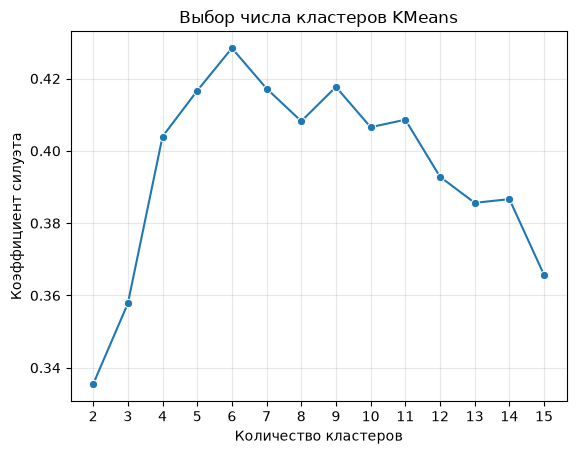

Лучшее число кластеров: 6
Коэффициент силуэта: 0.428


In [16]:
sns.lineplot(
    data=results_df,
    x="n_clusters",
    y="silhouette_score",
    marker="o"
)
plt.xticks(range(2, 16))
plt.xlabel("Количество кластеров")
plt.ylabel("Коэффициент силуэта")
plt.title("Выбор числа кластеров KMeans")
plt.grid(alpha=0.3)
plt.show()

best_row = results_df.loc[results_df["silhouette_score"].idxmax()]
best_k = int(best_row["n_clusters"])
best_kmeans = models[best_k]

print(f"Лучшее число кластеров: {best_k}")
print(f"Коэффициент силуэта: {best_row['silhouette_score']:.3f}")

**Вывод:** Среди вариантов KMeans с числом кластеров от 2 до 15 максимальный силуэт получен при 6 кластерах — 0,428. При увеличении числа кластеров от 2 до 6 показатель растёт; дальнейшее увеличение не даёт более высокого результата. Следующий по качеству вариант — 9 кластеров с силуэтом 0,418. Для дальнейшего сравнения выбрана модель с 6 кластерами. Обучение проведено на 200 клиентах после удаления строк с пропусками и стандартизации трёх числовых признаков.

## 5. Сравнение с агломеративной кластеризацией

Проверим метод Уорда для того же диапазона числа кластеров на той же стандартизированной матрице. Это позволяет сравнить два алгоритма без изменения подготовки данных.

In [17]:
agg_models = {}
agg_results = []

for k in range(2, 16):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    agg_models[k] = model
    agg_results.append({"n_clusters": k, "silhouette_score": score})

agg_results_df = pd.DataFrame(agg_results)
agg_results_df

,n_clusters,silhouette_score
0,2,0.317957
1,3,0.321489
2,4,0.361451
3,5,0.390028
4,6,0.420117
5,7,0.398295
6,8,0.366479
7,9,0.375385
8,10,0.380889
9,11,0.381198


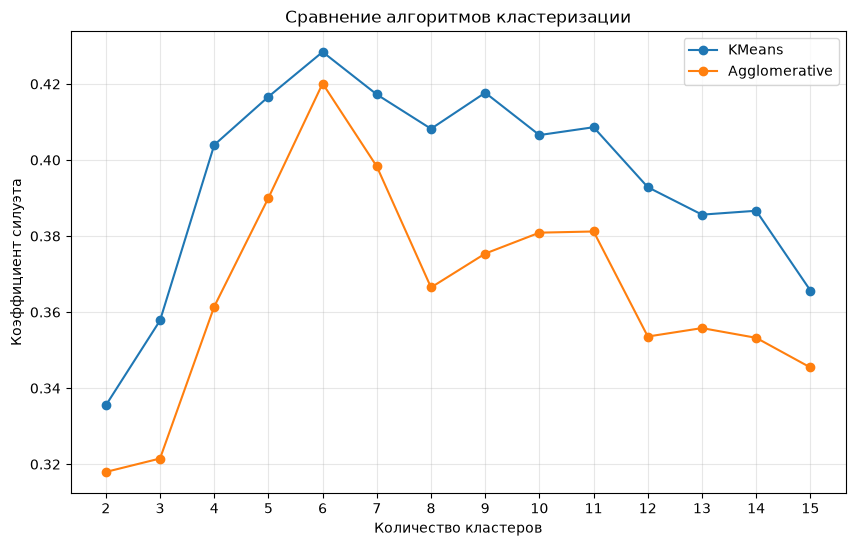

Лучшее число кластеров: 6
Коэффициент силуэта: 0.420


In [18]:
plt.figure(figsize=(10, 6))

plt.plot(
    results_df["n_clusters"], 
    results_df["silhouette_score"], 
    marker="o", 
    label="KMeans"
)

plt.plot(
    agg_results_df["n_clusters"], 
    agg_results_df["silhouette_score"], 
    marker="o", 
    label="Agglomerative"
)

plt.xticks(range(2, 16))
plt.xlabel("Количество кластеров")
plt.ylabel("Коэффициент силуэта")
plt.title("Сравнение алгоритмов кластеризации")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best_agg_row = agg_results_df.loc[
    agg_results_df["silhouette_score"].idxmax()
]
best_agg_k = int(best_agg_row["n_clusters"])
best_agg_model = agg_models[best_agg_k]

print(f"Лучшее число кластеров: {best_agg_k}")
print(f"Коэффициент силуэта: {best_agg_row['silhouette_score']:.3f}")

**Вывод:** Для агломеративной кластеризации с методом Уорда максимальный силуэт получен при 6 кластерах — 0,420. На той же матрице признаков KMeans с 6 кластерами даёт 0,428. Разница составляет около 0,008 в пользу KMeans. Для проверки понижения размерности выбран KMeans как лучший из двух алгоритмов по этому критерию.

## 6. Проверка понижения размерности с PCA

Снизим размерность до двух компонент, оценим сохранённую долю дисперсии и заново подберём число кластеров KMeans. Силуэт в двумерном пространстве характеризует другую систему расстояний, поэтому его изменение нельзя автоматически считать улучшением сегментации.

In [19]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("По компонентам:", pca.explained_variance_ratio_)
print(f"Всего сохранено: {pca.explained_variance_ratio_.sum():.1%}")

По компонентам: [0.44266167 0.33308378]
Всего сохранено: 77.6%


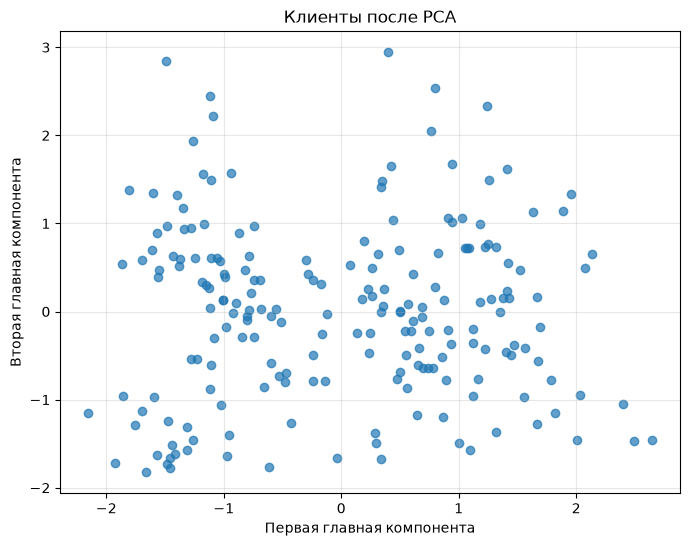

In [20]:
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.7)

plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.title("Клиенты после PCA")
plt.grid(alpha=0.3)
plt.show()

In [21]:
pca_models = {}
pca_results = []

for k in range(2, 16):
    model = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_pca)
    score = silhouette_score(X_pca, labels)

    pca_models[k] = model
    pca_results.append({"n_clusters": k, "silhouette_score": score})

pca_results_df = pd.DataFrame(pca_results)
pca_results_df

,n_clusters,silhouette_score
0,2,0.425633
1,3,0.413624
2,4,0.420929
3,5,0.393083
4,6,0.377470
5,7,0.387126
6,8,0.397646
7,9,0.389927
8,10,0.403817
9,11,0.379746


In [22]:
best_pca_row = pca_results_df.loc[
    pca_results_df["silhouette_score"].idxmax()
]

best_pca_k = int(best_pca_row["n_clusters"])
best_pca_model = pca_models[best_pca_k]

print(f"Лучшее число кластеров: {best_pca_k}")
print(f"Силуэт после PCA: {best_pca_row['silhouette_score']:.3f}")

Лучшее число кластеров: 2
Силуэт после PCA: 0.426


**Вывод:** Две компоненты PCA сохраняют 77,6% дисперсии исходных стандартизированных признаков. После понижения размерности максимальный силуэт KMeans составляет 0,426 при 2 кластерах. Это немного ниже результата без PCA: 0,428 при 6 кластерах. Улучшить максимальное значение силуэта не удалось. Поскольку расстояния рассчитаны в разных пространствах, сравнение дополняется интерпретацией групп. Для итогового описания клиентов выбран KMeans без PCA с 6 кластерами.

## 7. Профили сегментов и маркетинговые гипотезы

Для итоговой модели KMeans без PCA добавим номера кластеров к копии очищенных данных. Сопоставим размеры групп, средние и медианы числовых признаков, а также наиболее частое значение пола. Тепловая карта показывает средние стандартизированных признаков; таблица профилей — значения в исходных единицах.

In [23]:
df_clusters = df.copy()
df_clusters["cluster"] = best_kmeans.predict(X_scaled)

In [24]:
cluster_profile = df_clusters.groupby("cluster").agg(
    clients=("customer_id", "size"),
    age_mean=("age", "mean"),
    age_median=("age", "median"),
    income_mean=("annual_income", "mean"),
    income_median=("annual_income", "median"),
    spending_mean=("spending_score", "mean"),
    spending_median=("spending_score", "median"),
    gender_mode=("gender", lambda s: s.mode().tolist())
)

cluster_profile.round(1)

,clients,age_mean,age_median,income_mean,income_median,spending_mean,spending_median,gender_mode
cluster,,,,,,,,
0,45,56.3,54.0,54.3,54.0,49.1,49.0,[Female]
1,39,26.8,26.0,57.1,60.0,48.1,50.0,[Female]
2,33,41.9,43.0,88.9,86.0,17.0,16.0,[Male]
3,39,32.7,32.0,86.5,79.0,82.1,83.0,[Female]
4,23,25.0,23.0,25.3,24.0,77.6,77.0,[Female]
5,21,45.5,46.0,26.3,25.0,19.4,15.0,[Female]


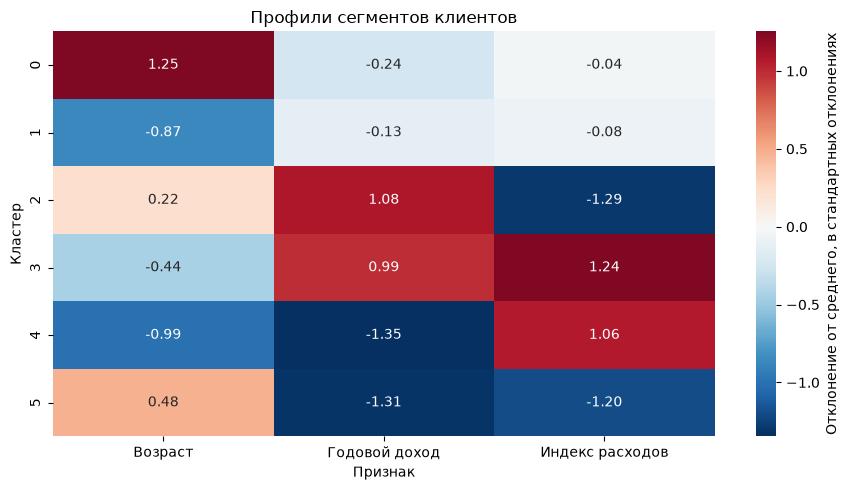

In [25]:
scaled_profile = pd.DataFrame(
    X_scaled,
    columns=features,
    index=df_clusters.index
)

scaled_profile["cluster"] = df_clusters["cluster"]

cluster_means = scaled_profile.groupby("cluster")[features].mean()

plt.figure(figsize=(9, 5))

sns.heatmap(
    cluster_means,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    xticklabels=["Возраст", "Годовой доход", "Индекс расходов"],
    cbar_kws={"label": "Отклонение от среднего, в стандартных отклонениях"}
)

plt.title("Профили сегментов клиентов")
plt.xlabel("Признак")
plt.ylabel("Кластер")
plt.tight_layout()
plt.show()

**Вывод:** KMeans без PCA разделил 200 клиентов на шесть сегментов. При выборе числа кластеров от 2 до 15 эта модель дала максимальный силуэт — 0,428.

| Кластер | Клиентов | Средний возраст, лет | Средний доход, тыс. $ | Средний индекс расходов | Профиль |
|---|---:|---:|---:|---:|---|
| 0 | 45 | 56,3 | 54,3 | 49,1 | Более старшие клиенты с доходом немного ниже среднего и средней активностью |
| 1 | 39 | 26,8 | 57,1 | 48,1 | Молодые клиенты со средними доходом и активностью |
| 2 | 33 | 41,9 | 88,9 | 17,0 | Высокий доход сочетается с низкой активностью |
| 3 | 39 | 32,7 | 86,5 | 82,1 | Клиенты с высокими доходом и активностью |
| 4 | 23 | 25,0 | 25,3 | 77,6 | Молодые клиенты с низким доходом и высокой активностью |
| 5 | 21 | 45,5 | 26,3 | 19,4 | Клиенты с низкими доходом и активностью |

Кластеры 0 и 1 близки по доходу и индексу расходов, но различаются по возрасту. Кластеры 2 и 3 имеют сходный высокий доход, однако противоположную покупательскую активность. У кластеров 4 и 5 доходы также близки, а возраст и индекс расходов заметно различаются. Возраст помог уточнить группы, которые на диаграмме дохода и расходов выглядят похожими.

Наиболее частый пол в кластере 2 — мужской, в остальных — женский. Пол использован только для описания сегментов. Таблица содержит средние в исходных единицах измерения, а тепловая карта — средние стандартизированных признаков.

Для кластера 2 можно проверить персональные предложения для повышения активности, для кластера 3 — программы удержания, для кластера 4 — доступные акции. Для кластера 5 можно проверить предложения с понятной экономией; для кластеров 0 и 1 — разные варианты коммуникации с учётом возраста. Это маркетинговые гипотезы, их эффективность нужно проверять экспериментально. Индекс расходов — условная оценка активности; он не позволяет напрямую определить суммы покупок или прибыльность клиентов.